#1. Project Introduction
# Student Dropout and Academic Success Prediction Using Random Forest

## Introduction

This project develops a machine learning-based system to analyze student
information and predict academic outcomes.

The system classifies students into three categories:

- Dropout
- Enrolled
- Graduate

The project uses Python for Data Science concepts including Pandas, NumPy,
data preprocessing, statistical analysis, data visualization and
Scikit-learn.

Random Forest is used as the machine learning technique and represents
the advanced topic beyond the prescribed syllabus.

#2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


#3. Load Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data.csv to data.csv


In [ ]:
df = pd.read_csv("data.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (4424, 37)


#4. Dataset Understanding

In [ ]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
df.tail()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [ ]:
df.sample(5)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
874,1,1,1,9003,1,1,148.0,1,1,19,...,0,6,8,4,14.500000,0,8.9,1.4,3.51,Graduate
2382,1,7,1,9119,1,40,130.0,1,1,1,...,2,5,7,5,15.142857,0,11.1,0.6,2.02,Dropout
1966,1,1,1,9085,1,1,120.0,1,1,19,...,0,5,8,3,13.000000,1,9.4,-0.8,-3.12,Graduate
1312,1,1,1,9773,1,1,151.0,1,38,37,...,0,6,6,6,12.833333,0,10.8,1.4,1.74,Graduate
602,1,7,1,9500,1,40,170.0,1,1,1,...,3,8,9,8,15.744444,0,16.2,0.3,-0.92,Graduate


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4424
Number of columns: 37


In [ ]:
print("Column names:")
for column in df.columns:
    print(column)

Column names:
Marital status
Application mode
Application order
Course
Daytime/evening attendance	
Previous qualification
Previous qualification (grade)
Nacionality
Mother's qualification
Father's qualification
Mother's occupation
Father's occupation
Admission grade
Displaced
Educational special needs
Debtor
Tuition fees up to date
Gender
Scholarship holder
Age at enrollment
International
Curricular units 1st sem (credited)
Curricular units 1st sem (enrolled)
Curricular units 1st sem (evaluations)
Curricular units 1st sem (approved)
Curricular units 1st sem (grade)
Curricular units 1st sem (without evaluations)
Curricular units 2nd sem (credited)
Curricular units 2nd sem (enrolled)
Curricular units 2nd sem (evaluations)
Curricular units 2nd sem (approved)
Curricular units 2nd sem (grade)
Curricular units 2nd sem (without evaluations)
Unemployment rate
Inflation rate
GDP
Target


In [ ]:
missing_values = df.isnull().sum()

print("Total missing values: -\n\n", missing_values)

Total missing values: -

 Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                    

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
print(df["Target"].value_counts())

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [ ]:
print(df["Target"].value_counts(normalize=True) * 100)

Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [ ]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique values:", df[column].nunique())
    print("Sample values:", df[column].unique()[:10])


Marital status
Unique values: 6
Sample values: [1 2 4 3 5 6]

Application mode
Unique values: 18
Sample values: [17 15  1 39 18 53 44 51 43  7]

Application order
Unique values: 8
Sample values: [5 1 2 4 3 6 9 0]

Course
Unique values: 17
Sample values: [ 171 9254 9070 9773 8014 9991 9500 9238 9670 9853]

Daytime/evening attendance	
Unique values: 2
Sample values: [1 0]

Previous qualification
Unique values: 17
Sample values: [ 1 19 42 39 10  3 40  2  4 12]

Previous qualification (grade)
Unique values: 101
Sample values: [122.  160.  100.  133.1 142.  119.  137.  138.  139.  136. ]

Nacionality
Unique values: 21
Sample values: [  1  62   6  41  26 103  13  25  21 101]

Mother's qualification
Unique values: 29
Sample values: [19  1 37 38  3  4 42  2 34 12]

Father's qualification
Unique values: 34
Sample values: [12  3 37 38  1 19  5  4 34  2]

Mother's occupation
Unique values: 32
Sample values: [  5   3   9   7   4   1 125   0   6   2]

Father's occupation
Unique values: 46
Sample v

In [ ]:
feature_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Unique Values": df.nunique(),
    "Missing Values": df.isnull().sum()
})

feature_summary

,Data Type,Unique Values,Missing Values
Marital status,int64,6,0
Application mode,int64,18,0
Application order,int64,8,0
Course,int64,17,0
Daytime/evening attendance\t,int64,2,0
Previous qualification,int64,17,0
Previous qualification (grade),float64,101,0
Nacionality,int64,21,0
Mother's qualification,int64,29,0
Father's qualification,int64,34,0


In [ ]:
target_counts = df["Target"].value_counts()

print("Target Distribution:")
print(target_counts)

Target Distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [ ]:
target_percentages = df["Target"].value_counts(normalize=True) * 100

print("\nTarget Distribution (%):")
print(target_percentages.round(2))


Target Distribution (%):
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


#5. Data Cleaning

In [ ]:
print(df.columns.tolist())

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [ ]:
df.dtypes

,0
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64


In [ ]:
df["Target"] = df["Target"].str.strip()

print("Unique Target values:")
print(df["Target"].unique())

Unique Target values:
['Dropout' 'Graduate' 'Enrolled']


In [ ]:
# Final data cleaning verification

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
print("Target values:", df["Target"].unique())

Dataset shape: (4424, 37)
Total missing values: 0
Total duplicate rows: 0
Target values: ['Dropout' 'Graduate' 'Enrolled']


#6. Exploratory Data Analysis

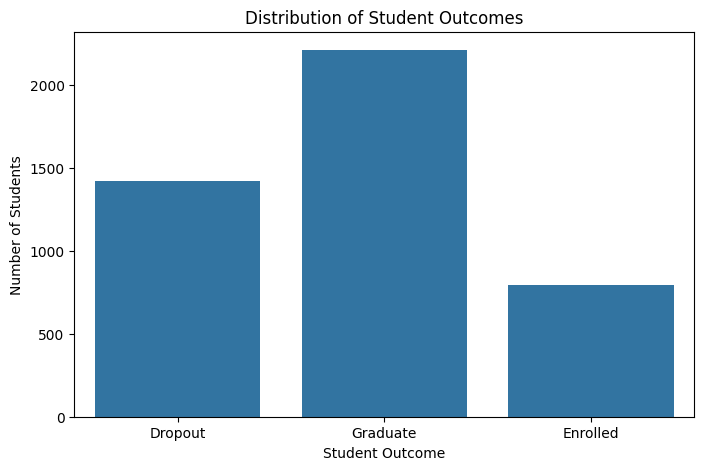

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Target")

plt.title("Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")

plt.show()

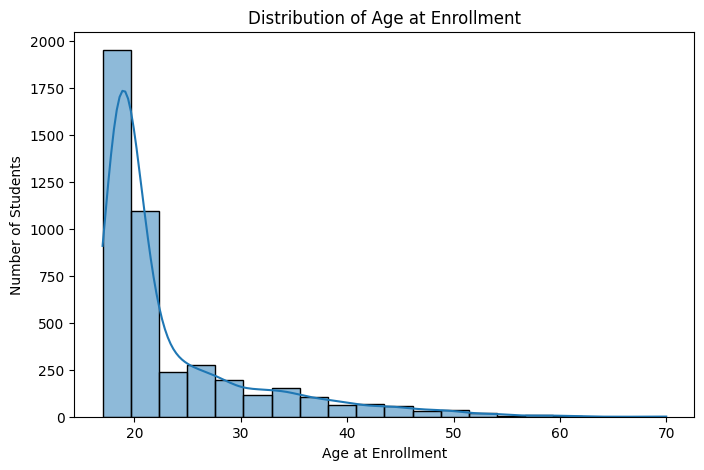

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age at enrollment", bins=20, kde=True)

plt.title("Distribution of Age at Enrollment")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")
plt.show()

In [ ]:
print("Age Statistics:")
print(df["Age at enrollment"].describe())

Age Statistics:
count    4424.000000
mean       23.265145
std         7.587816
min        17.000000
25%        19.000000
50%        20.000000
75%        25.000000
max        70.000000
Name: Age at enrollment, dtype: float64


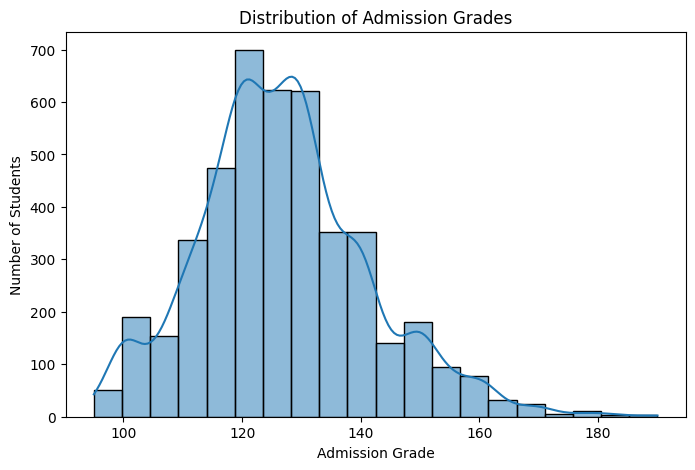

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Admission grade", bins=20, kde=True)

plt.title("Distribution of Admission Grades")
plt.xlabel("Admission Grade")
plt.ylabel("Number of Students")
plt.show()

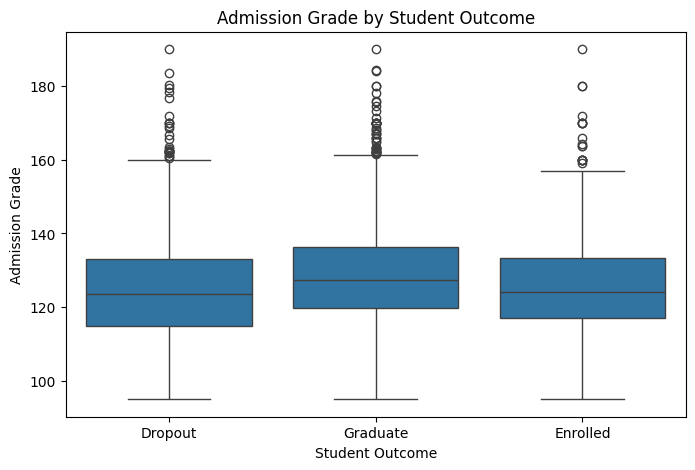

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Target", y="Admission grade")

plt.title("Admission Grade by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")
plt.show()

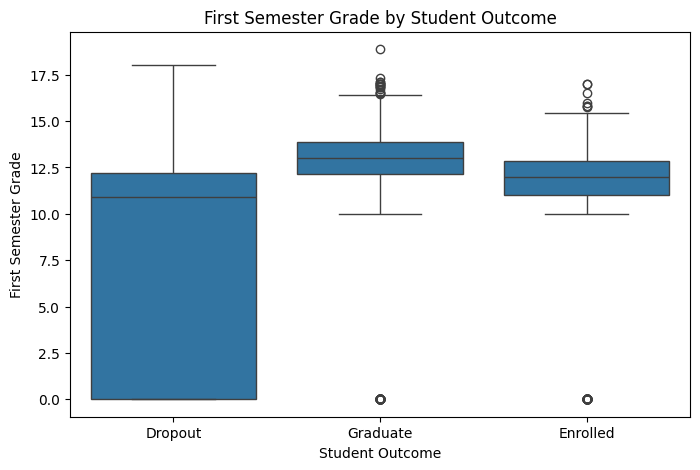

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)"
)

plt.title("First Semester Grade by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("First Semester Grade")
plt.show()

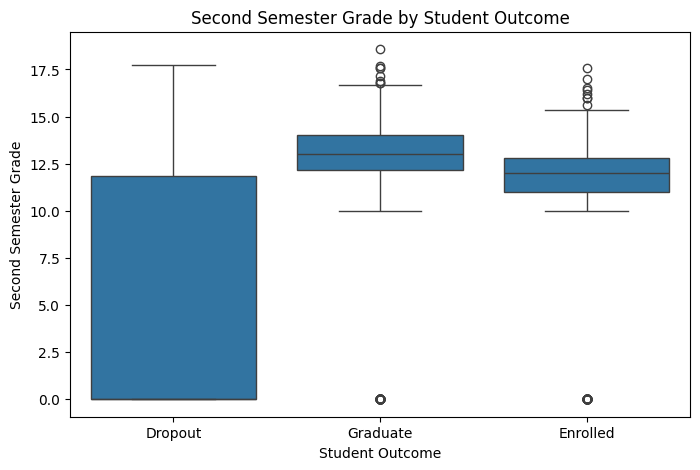

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 2nd sem (grade)"
)

plt.title("Second Semester Grade by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Second Semester Grade")
plt.show()

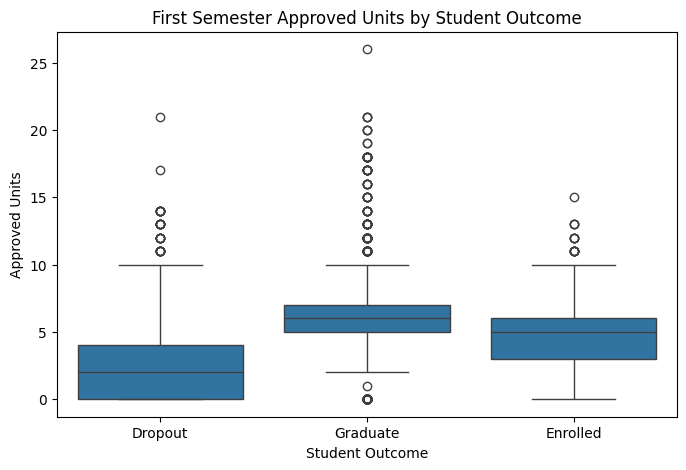

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (approved)"
)

plt.title("First Semester Approved Units by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Approved Units")
plt.show()

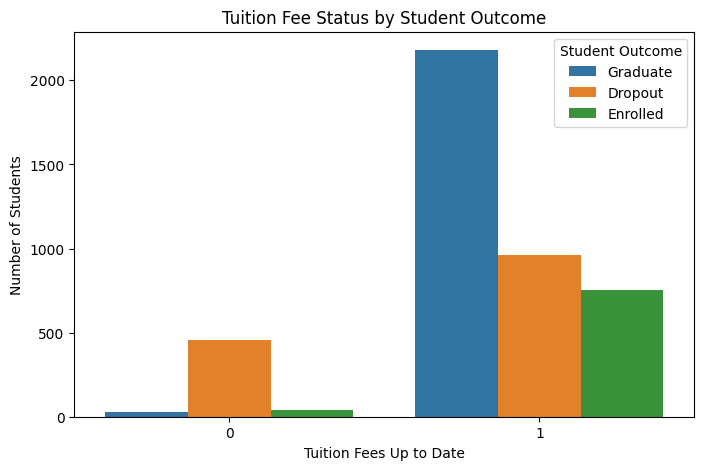

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Tuition fees up to date",
    hue="Target"
)

plt.title("Tuition Fee Status by Student Outcome")
plt.xlabel("Tuition Fees Up to Date")
plt.ylabel("Number of Students")
plt.legend(title="Student Outcome")
plt.show()

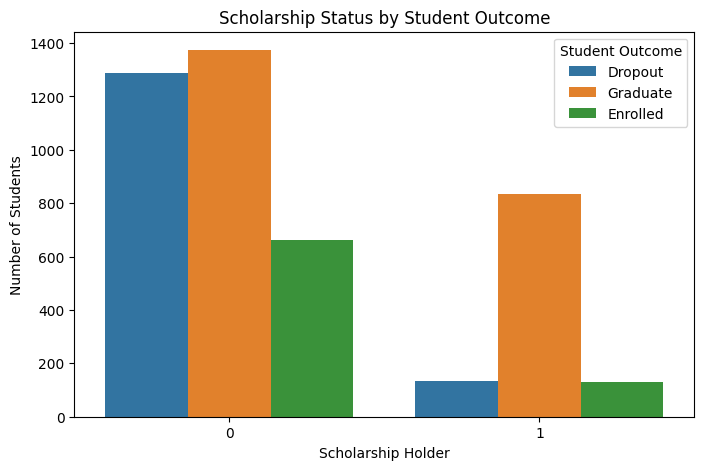

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Scholarship holder",
    hue="Target"
)

plt.title("Scholarship Status by Student Outcome")
plt.xlabel("Scholarship Holder")
plt.ylabel("Number of Students")
plt.legend(title="Student Outcome")
plt.show()

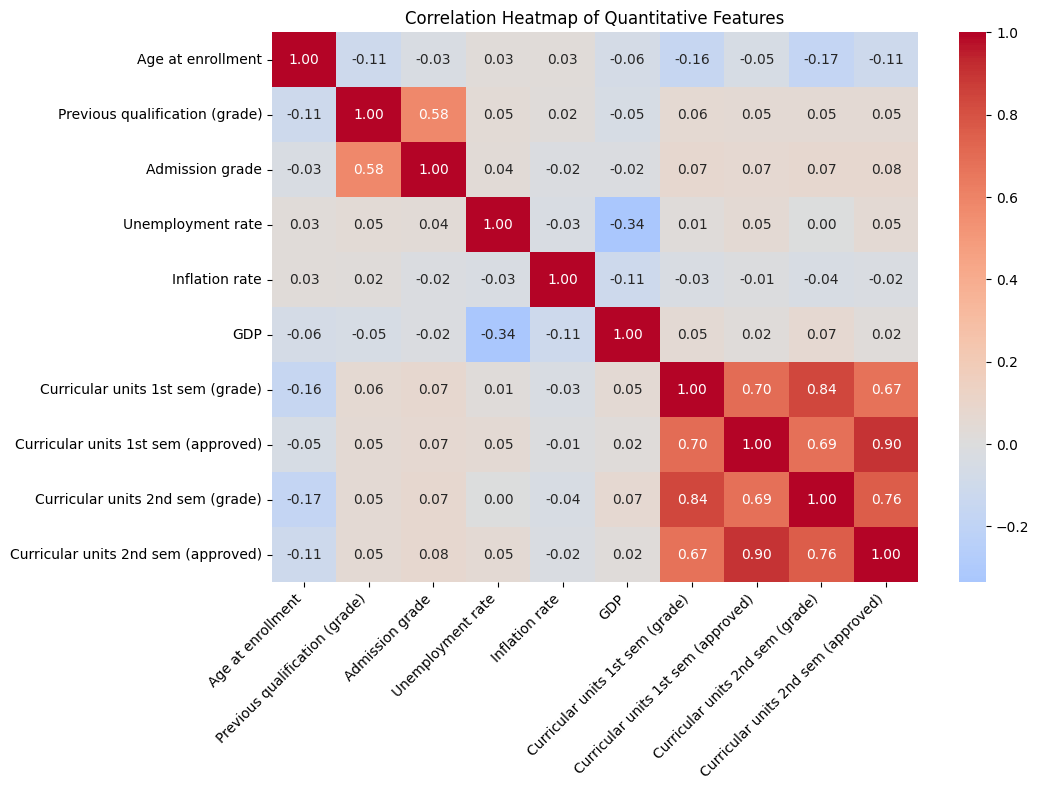

In [ ]:
# Correlation heatmap of quantitative features

quantitative_features = [
    "Age at enrollment",
    "Previous qualification (grade)",
    "Admission grade",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (approved)"
]

correlation_matrix = df[quantitative_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Quantitative Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#7. Statistical Analysis

In [ ]:
# Mean values of important variables by student outcome

grouped_stats = df.groupby("Target")[
    [
        "Age at enrollment",
        "Admission grade",
        "Curricular units 1st sem (grade)",
        "Curricular units 1st sem (approved)",
        "Curricular units 2nd sem (grade)",
        "Curricular units 2nd sem (approved)"
    ]
].mean()

print(grouped_stats)

          Age at enrollment  Admission grade  \
Target                                         
Dropout           26.068966       124.961365   
Enrolled          22.369018       125.534257   
Graduate          21.783612       128.794432   

          Curricular units 1st sem (grade)  \
Target                                       
Dropout                           7.256656   
Enrolled                         11.125257   
Graduate                         12.643655   

          Curricular units 1st sem (approved)  \
Target                                          
Dropout                              2.551724   
Enrolled                             4.318640   
Graduate                             6.232232   

          Curricular units 2nd sem (grade)  \
Target                                       
Dropout                           5.899339   
Enrolled                         11.117364   
Graduate                         12.697276   

          Curricular units 2nd sem (approved)  
Tar

In [ ]:
# Median values by student outcome

median_stats = df.groupby("Target")[
    [
        "Age at enrollment",
        "Admission grade",
        "Curricular units 1st sem (grade)",
        "Curricular units 1st sem (approved)",
        "Curricular units 2nd sem (grade)",
        "Curricular units 2nd sem (approved)"
    ]
].median()

print(median_stats)

          Age at enrollment  Admission grade  \
Target                                         
Dropout                23.0            123.6   
Enrolled               20.0            124.1   
Graduate               19.0            127.4   

          Curricular units 1st sem (grade)  \
Target                                       
Dropout                          10.928571   
Enrolled                         12.000000   
Graduate                         13.000000   

          Curricular units 1st sem (approved)  \
Target                                          
Dropout                                   2.0   
Enrolled                                  5.0   
Graduate                                  6.0   

          Curricular units 2nd sem (grade)  \
Target                                       
Dropout                                0.0   
Enrolled                              12.0   
Graduate                              13.0   

          Curricular units 2nd sem (approved)  
Tar

In [ ]:
# Standard deviation by student outcome

std_stats = df.groupby("Target")[
    [
        "Age at enrollment",
        "Admission grade",
        "Curricular units 1st sem (grade)",
        "Curricular units 1st sem (approved)",
        "Curricular units 2nd sem (grade)",
        "Curricular units 2nd sem (approved)"
    ]
].std()

print(std_stats)

          Age at enrollment  Admission grade  \
Target                                         
Dropout            8.704024        15.125159   
Enrolled           6.302672        13.792559   
Graduate           6.693218        14.071440   

          Curricular units 1st sem (grade)  \
Target                                       
Dropout                           6.031120   
Enrolled                          3.675084   
Graduate                          2.699027   

          Curricular units 1st sem (approved)  \
Target                                          
Dropout                              2.857588   
Enrolled                             2.289398   
Graduate                             2.583380   

          Curricular units 2nd sem (grade)  \
Target                                       
Dropout                           6.118740   
Enrolled                          3.601240   
Graduate                          2.685608   

          Curricular units 2nd sem (approved)  
Tar

In [ ]:
# Separate first-semester grades by target group

dropout_grade = df.loc[
    df["Target"] == "Dropout",
    "Curricular units 1st sem (grade)"
]

enrolled_grade = df.loc[
    df["Target"] == "Enrolled",
    "Curricular units 1st sem (grade)"
]

graduate_grade = df.loc[
    df["Target"] == "Graduate",
    "Curricular units 1st sem (grade)"
]

# Perform one-way ANOVA
f_statistic, p_value = stats.f_oneway(
    dropout_grade,
    enrolled_grade,
    graduate_grade
)

print("ANOVA F-statistic:", f_statistic)
print("ANOVA p-value:", p_value)

ANOVA F-statistic: 713.5173278989449
ANOVA p-value: 2.803051698802402e-269


#8. Data Visualization

In [ ]:
# Calculate percentage of each student outcome
target_percentage = df["Target"].value_counts(normalize=True) * 100

print("Student Outcome Percentage:")
print(target_percentage.round(2))

Student Outcome Percentage:
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


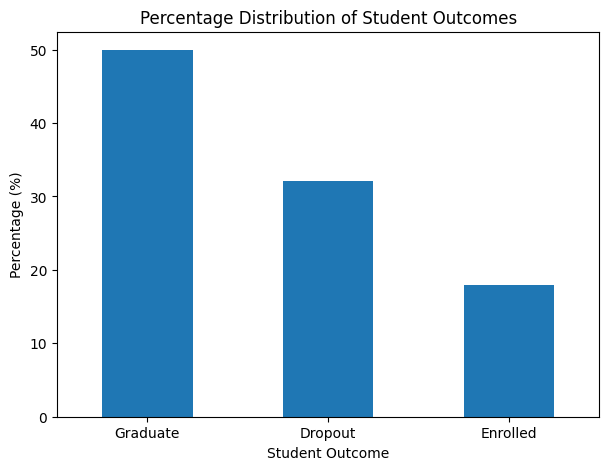

In [ ]:
plt.figure(figsize=(7, 5))

target_percentage.plot(kind="bar")

plt.title("Percentage Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Calculate average admission-related grades by outcome

admission_stats = df.groupby("Target")[
    [
        "Admission grade",
        "Previous qualification (grade)"
    ]
].mean()

print("Average Admission and Previous Qualification Grades:")
print(admission_stats)

Average Admission and Previous Qualification Grades:
          Admission grade  Previous qualification (grade)
Target                                                   
Dropout        124.961365                      131.114075
Enrolled       125.534257                      131.208438
Graduate       128.794432                      134.082707


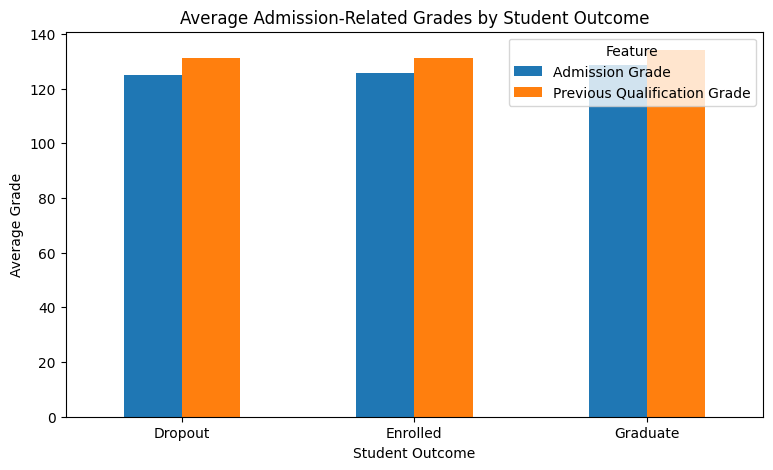

In [ ]:
# Visualize average admission-related grades

admission_stats.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Admission-Related Grades by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Average Grade")
plt.xticks(rotation=0)

plt.legend(
    ["Admission Grade", "Previous Qualification Grade"],
    title="Feature"
)

plt.show()

In [ ]:
# Prepare features for association analysis

semester_features = [
    col for col in df.columns
    if "Curricular units 1st sem" in col
    or "Curricular units 2nd sem" in col
]

X_analysis = df.drop(
    columns=semester_features + ["Target"]
)

y_analysis = df["Target"]

print("Number of features:", X_analysis.shape[1])
print("Student outcome classes:", y_analysis.unique())


Number of features: 24
Student outcome classes: ['Dropout' 'Graduate' 'Enrolled']


In [ ]:
# Calculate mutual information between features and outcome.

from sklearn.feature_selection import mutual_info_classif

continuous_features = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Treat coded categories as discrete features
discrete_mask = [
    col not in continuous_features
    for col in X_analysis.columns
]

mi_scores = mutual_info_classif(
    X_analysis,
    y_analysis,
    discrete_features=discrete_mask,
    random_state=42
)

print("Feature association scores calculated.")


Feature association scores calculated.


In [ ]:
# Rank features by mutual information.

feature_association = pd.Series(
    mi_scores,
    index=X_analysis.columns
).sort_values(ascending=False)

print("Top 10 Features Associated with Student Outcome:")
print(feature_association.head(10).round(4))


Top 10 Features Associated with Student Outcome:
Tuition fees up to date           0.0918
Course                            0.0665
Age at enrollment                 0.0580
Application mode                  0.0522
Scholarship holder                0.0492
Mother's occupation               0.0340
Previous qualification (grade)    0.0336
Admission grade                   0.0329
Father's occupation               0.0308
Debtor                            0.0289
dtype: float64


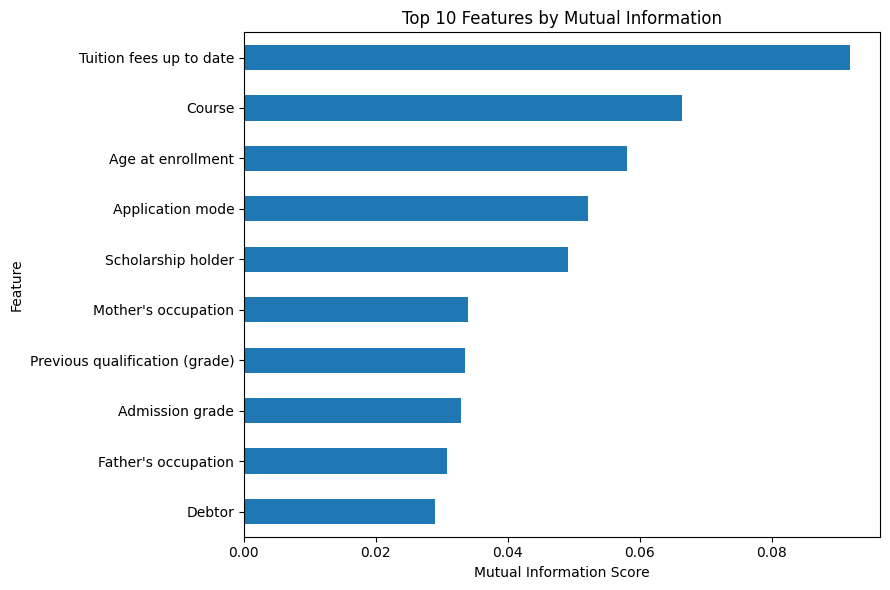

In [ ]:
# Visualize the top 10 associated features

top_features = feature_association.head(10).sort_values()

plt.figure(figsize=(9, 6))

top_features.plot(kind="barh")

plt.title("Top 10 Features by Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


#9. Data Preprocessing

In [ ]:
# Separate features and target
X = df.drop("Target", axis=1)
y = df["Target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4424, 36)
Target shape: (4424,)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Target classes:", label_encoder.classes_)
print("Encoded target values:", np.unique(y_encoded))

Target classes: ['Dropout' 'Enrolled' 'Graduate']
Encoded target values: [0 1 2]


In [ ]:
# Display the data types of the features
print(X.dtypes)

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender        

#10. Feature Selection

In [ ]:
# Identify semester-performance features

semester_features = [
    col for col in X.columns
    if "Curricular units 1st sem" in col
    or "Curricular units 2nd sem" in col
]

print("Semester-performance features:")
for feature in semester_features:
    print("-", feature)

print("\nTotal semester-performance features:", len(semester_features))

Semester-performance features:
- Curricular units 1st sem (credited)
- Curricular units 1st sem (enrolled)
- Curricular units 1st sem (evaluations)
- Curricular units 1st sem (approved)
- Curricular units 1st sem (grade)
- Curricular units 1st sem (without evaluations)
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (enrolled)
- Curricular units 2nd sem (evaluations)
- Curricular units 2nd sem (approved)
- Curricular units 2nd sem (grade)
- Curricular units 2nd sem (without evaluations)

Total semester-performance features: 12


In [ ]:
# Remove semester-performance features
X_selected = X.drop(columns=semester_features)

print("Original number of features:", X.shape[1])
print("Selected number of features:", X_selected.shape[1])

Original number of features: 36
Selected number of features: 24


In [ ]:
print("Selected features:")
for i, feature in enumerate(X_selected.columns, start=1):
    print(f"{i}. {feature}")

Selected features:
1. Marital status
2. Application mode
3. Application order
4. Course
5. Daytime/evening attendance
6. Previous qualification
7. Previous qualification (grade)
8. Nacionality
9. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Unemployment rate
23. Inflation rate
24. GDP


In [ ]:
# Final feature-selection check

print("\nFinal feature matrix shape:", X_selected.shape)
print("Target shape:", y_encoded.shape)


Final feature matrix shape: (4424, 24)
Target shape: (4424,)


#11. Train-Test Split

In [ ]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (3539, 24)
Testing set shape: (885, 24)


In [ ]:
print("Training target distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts())

Training target distribution:
2    1767
0    1137
1     635
Name: count, dtype: int64

Testing target distribution:
2    442
0    284
1    159
Name: count, dtype: int64


#12. Random Forest Model

In [ ]:
# Create Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [ ]:
# Train the Random Forest model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Predict student outcomes
y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 885


#13. Model Evaluation

In [ ]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

Random Forest Accuracy: 0.6338983050847458
Random Forest Accuracy: 63.39%


In [ ]:
# Generate classification report
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

Classification Report:

              precision    recall  f1-score   support

     Dropout       0.66      0.62      0.64       284
    Enrolled       0.37      0.15      0.21       159
    Graduate       0.65      0.82      0.73       442

    accuracy                           0.63       885
   macro avg       0.56      0.53      0.53       885
weighted avg       0.60      0.63      0.61       885



In [ ]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[176  16  92]
 [ 35  24 100]
 [ 56  25 361]]


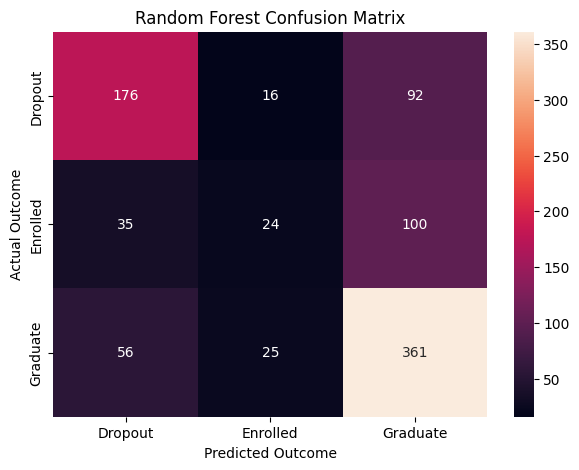

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

#14. Feature Importance

In [ ]:
# Get feature importance from Random Forest
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_selected.columns
)

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
Admission grade                   0.098930
Previous qualification (grade)    0.085338
Age at enrollment                 0.083948
Course                            0.078389
Tuition fees up to date           0.076288
Father's occupation               0.067294
Mother's occupation               0.058326
GDP                               0.047925
Father's qualification            0.047704
Application mode                  0.047228
Mother's qualification            0.046585
Unemployment rate                 0.045101
Inflation rate                    0.042314
Scholarship holder                0.036879
Application order                 0.029215
Gender                            0.025022
Debtor                            0.021492
Displaced                         0.019625
Previous qualification            0.015936
Marital status                    0.010128
Daytime/evening attendance        0.007244
Nacionality                       0.003989
International                     

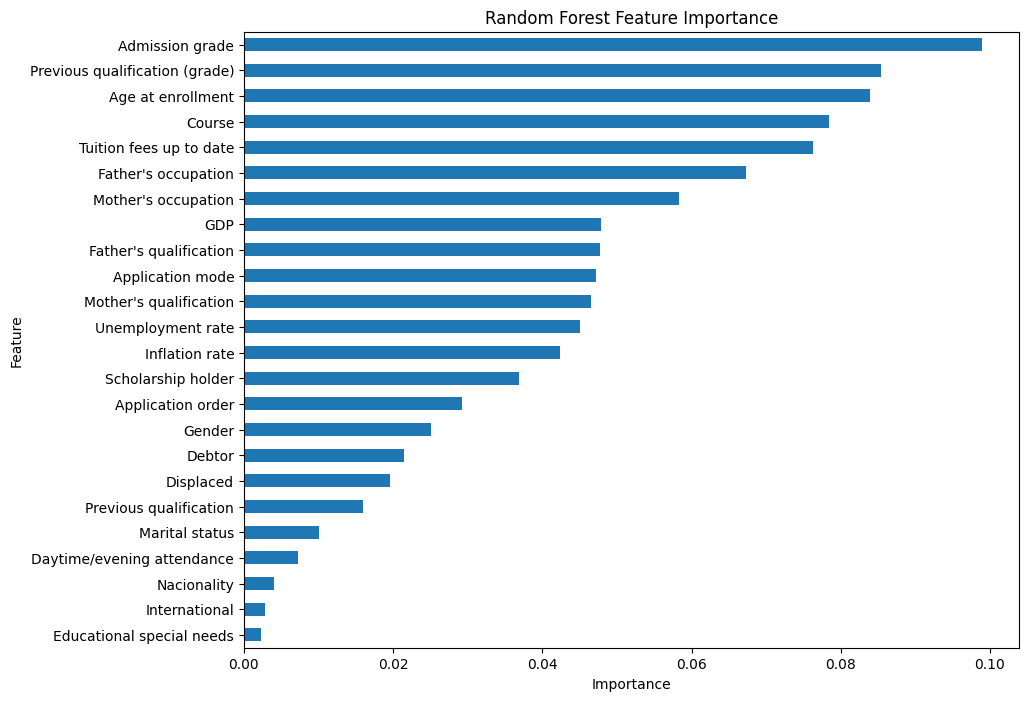

In [ ]:
# Plot feature importance
plt.figure(figsize=(10, 8))

feature_importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [ ]:
# Display top 10 most important features
print("Top 10 Most Important Features:")
print(feature_importance.head(10))

Top 10 Most Important Features:
Admission grade                   0.098930
Previous qualification (grade)    0.085338
Age at enrollment                 0.083948
Course                            0.078389
Tuition fees up to date           0.076288
Father's occupation               0.067294
Mother's occupation               0.058326
GDP                               0.047925
Father's qualification            0.047704
Application mode                  0.047228
dtype: float64


#15. Student Outcome Prediction

In [ ]:
# Select one student from the test set
sample_student = X_test.iloc[[0]]

# Predict the student's outcome
sample_prediction = rf_model.predict(sample_student)

# Convert encoded prediction back to original label
predicted_outcome = label_encoder.inverse_transform(sample_prediction)

print("Predicted Student Outcome:", predicted_outcome[0])

Predicted Student Outcome: Graduate


In [ ]:
# Get prediction probabilities
prediction_probabilities = rf_model.predict_proba(sample_student)[0]

print("Prediction Probabilities:")

for class_name, probability in zip(
    label_encoder.classes_,
    prediction_probabilities
):
    print(f"{class_name}: {probability:.2%}")

Prediction Probabilities:
Dropout: 20.00%
Enrolled: 12.00%
Graduate: 68.00%


In [ ]:
# Display actual and predicted outcome

actual_outcome = label_encoder.inverse_transform([y_test[0]])

print("Actual Student Outcome:", actual_outcome[0])
print("Predicted Student Outcome:", predicted_outcome[0])

Actual Student Outcome: Graduate
Predicted Student Outcome: Graduate


## 16. Conclusion

This project developed a machine learning system to predict student academic
outcomes using Random Forest.

The dataset contained 4,424 student records and 36 input features. After
feature selection, 24 features were used for model training. Semester-based
academic performance features were excluded to make the prediction more
meaningful using information available around admission and enrollment.

The Random Forest model was trained using 80% of the data and evaluated on
20% unseen data.

The model achieved an accuracy of **63.39%**.

The model performed best for the Graduate class, with a recall of **82%**,
while the Enrolled class was more difficult to predict, with a recall of
**15%**.

Feature importance analysis showed that **Admission grade**, **Previous
qualification (grade)**, **Age at enrollment**, **Course**, and **Tuition
fees up to date** were among the most important features used by the model.

A sample student was also tested by the model. The actual outcome was
Graduate and the predicted outcome was also Graduate, with a prediction
probability of **68%** for the Graduate class.

Overall, the project demonstrates how Python, Pandas, data analysis,
visualization and Random Forest can be combined to analyze and predict
student academic outcomes.